# Đồ án Máy học – Online Retail II
## Notebook 01: Khám phá dữ liệu và xây dựng bảng RFM ban đầu

**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng.

**Mục tiêu của notebook:** hiểu dữ liệu giao dịch gốc, kiểm tra chất lượng, trực quan hóa các đặc điểm chính, nêu rõ quy tắc tiền xử lý và tạo bảng RFM ở mức khách hàng để dùng ở giai đoạn phân cụm.

> Đây là giai đoạn khởi đầu. Notebook chưa đưa ra kết luận thuật toán nào tốt nhất và chưa gán nhãn phân khúc cuối cùng. Các con số và biểu đồ phải được tạo bằng cách chạy trên dataset gốc, không điền kết quả giả.

## 1. Xác định bài toán

### Bối cảnh
Nhà bán lẻ trực tuyến có nhiều giao dịch trong thời gian dài. Nếu chỉ nhìn từng hóa đơn, khó nhận biết những nhóm khách hàng có giá trị và tần suất mua khác nhau. Phân khúc khách hàng có thể hỗ trợ doanh nghiệp lựa chọn cách chăm sóc phù hợp cho từng nhóm.

### Mục tiêu
Từ lịch sử giao dịch, tổng hợp đặc trưng ở mức khách hàng bằng RFM:

- **Recency (R):** số ngày từ lần mua gần nhất của khách hàng đến ngày tham chiếu.
- **Frequency (F):** số hóa đơn khác nhau mà khách hàng đã phát sinh trong dữ liệu.
- **Monetary (M):** tổng giá trị mua hàng, tính bằng số lượng nhân đơn giá.

Sau khi hoàn thành phần dữ liệu, giai đoạn sau sẽ dùng các đặc trưng này để thử nghiệm thuật toán gom cụm và diễn giải đặc điểm các cụm.

### Loại bài toán Machine Learning
Đây là bài toán **học không giám sát (clustering)** vì dữ liệu không cung cấp sẵn nhãn phân khúc đúng cho từng khách hàng.

### Câu hỏi nghiên cứu dự kiến
1. Tập khách hàng trong dữ liệu có khác biệt như thế nào về độ gần đây, tần suất và tổng giá trị mua?
2. Có thể hình thành những nhóm khách hàng có hành vi khác nhau từ các đặc trưng RFM không?
3. Các thuật toán phân cụm sẽ cho cấu trúc cụm và khả năng diễn giải khác nhau như thế nào?

## 2. Nguồn và mô tả dữ liệu

Nguồn chính thức: [Online Retail II – UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii).

Theo UCI, dữ liệu gồm **1.067.371 dòng giao dịch**, ghi nhận trong giai đoạn **01/12/2009–09/12/2011**. Dataset có giá trị thiếu. Các trường gốc gồm:

| Thuộc tính | Ý nghĩa |
|---|---|
| `InvoiceNo` | Mã hóa đơn; mã bắt đầu bằng `C` biểu thị hóa đơn hủy |
| `StockCode` | Mã sản phẩm |
| `Description` | Mô tả/tên sản phẩm |
| `Quantity` | Số lượng sản phẩm trong dòng giao dịch |
| `InvoiceDate` | Ngày và giờ phát sinh giao dịch |
| `Price` hoặc `UnitPrice` | Đơn giá, tính bằng bảng Anh (GBP) |
| `Customer ID` hoặc `CustomerID` | Mã khách hàng |
| `Country` | Quốc gia của khách hàng |

Tên cột có thể khác nhẹ tùy cách tải/đọc file, vì vậy notebook chuẩn hóa một số tên cột phổ biến trước khi phân tích.

**Trích dẫn dataset:** Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D

## 3. Chuẩn bị môi trường và đọc dữ liệu

Nếu chưa có file Excel, cell tiếp theo sẽ gọi script tải dataset gốc từ UCI và lưu vào `data/raw/`. Có thể tải thủ công từ trang UCI và đặt file `.xlsx` vào cùng thư mục.

In [1]:
from pathlib import Path
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

warnings.filterwarnings("ignore", category=FutureWarning)
display(HTML("""<style>
.dataframe { margin-left: left !important; margin-right: left !important; }
.dataframe th, .dataframe td { text-align: center !important; }
</style>"""))
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"

for folder in (DATA_DIR, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)


In [2]:
def find_workbook(data_dir: Path):
    files = list(data_dir.rglob("*.xlsx"))
    if not files:
        return None
    preferred = [p for p in files if "online" in p.name.lower() and "retail" in p.name.lower()]
    return preferred[0] if preferred else files[0]

DATA_FILE = find_workbook(DATA_DIR)
if DATA_FILE is None:
    downloader = PROJECT_ROOT / "src" / "download_dataset.py"
    if not downloader.exists():
        raise FileNotFoundError(
            "Không tìm thấy file .xlsx trong data/raw/ và không tìm thấy src/download_dataset.py. "
            "Hãy chạy notebook từ thư mục gốc của dự án hoặc tải dataset từ trang UCI."
        )
    print("Chưa thấy dataset. Đang gọi script tải dữ liệu từ UCI...")
    subprocess.run([sys.executable, str(downloader)], check=True)
    DATA_FILE = find_workbook(DATA_DIR)

if DATA_FILE is None:
    raise FileNotFoundError(
        "Không tìm thấy file Excel sau khi tải. Hãy tải Online Retail II từ UCI "
        "và đặt file .xlsx trong thư mục data/raw/."
    )

In [3]:
excel_sheets = pd.read_excel(DATA_FILE, sheet_name=None, engine="openpyxl")
print("Các sheet trong file:", list(excel_sheets.keys()))

raw_df = pd.concat(
    [sheet.assign(_source_sheet=sheet_name) for sheet_name, sheet in excel_sheets.items()],
    ignore_index=True,
    sort=False,
)
print(f"Kích thước dữ liệu vừa đọc: {raw_df.shape[0]:,} dòng × {raw_df.shape[1] - 1:,} cột dữ liệu (chưa tính cột theo dõi sheet).")
display(raw_df.head())

Các sheet trong file: ['Year 2009-2010', 'Year 2010-2011']
Kích thước dữ liệu vừa đọc: 1,067,371 dòng × 8 cột dữ liệu (chưa tính cột theo dõi sheet).


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,_source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


## 4. Chuẩn hóa tên cột và kiểu dữ liệu

Các tên cột được quy về một bộ tên thống nhất để các cell sau không phụ thuộc cách viết có khoảng trắng hay tên `Price`/`UnitPrice`. Việc chuẩn hóa tên không làm thay đổi ý nghĩa dữ liệu.

In [4]:
def normalize_column_name(name: str) -> str:
    return "".join(char.lower() for char in str(name).strip() if char.isalnum())

column_aliases = {
    "invoiceno": "InvoiceNo",
    "invoice": "InvoiceNo",
    "stockcode": "StockCode",
    "description": "Description",
    "quantity": "Quantity",
    "invoicedate": "InvoiceDate",
    "transactiontime": "InvoiceDate",
    "unitprice": "UnitPrice",
    "price": "UnitPrice",
    "customerid": "CustomerID",
    "country": "Country",
}

rename_map = {
    old_name: column_aliases.get(normalize_column_name(old_name), str(old_name).strip())
    for old_name in raw_df.columns
    if old_name != "_source_sheet"
}
df = raw_df.rename(columns=rename_map).copy()

required_columns = ["InvoiceNo", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
missing_required = [column for column in required_columns if column not in df.columns]
if missing_required:
    raise ValueError(
        f"Thiếu các cột bắt buộc: {missing_required}. Các cột hiện có: {list(df.columns)}. "
        "Hãy kiểm tra lại đúng dataset Online Retail II."
    )

# Chuyển về kiểu phù hợp và để pandas nhận diện giá trị thiếu.
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = df["CustomerID"].replace(r"^\s*$", np.nan, regex=True)

print("Các cột sau chuẩn hóa:")
print(df.columns.tolist())
print("\nKiểu dữ liệu:")
display(df.dtypes.rename("dtype").to_frame())

Các cột sau chuẩn hóa:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', '_source_sheet']

Kiểu dữ liệu:


,dtype
InvoiceNo,string
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str
_source_sheet,str


## 5. Khảo sát tổng quan dữ liệu (EDA)

Trước khi lọc dữ liệu, cần mô tả dữ liệu gốc để tránh bỏ qua vấn đề chất lượng. Các thống kê dưới đây được tính trực tiếp từ file đã tải.

In [5]:
print(f"Số dòng: {len(df):,}")
print(f"Số cột dữ liệu: {len([c for c in df.columns if c != '_source_sheet']):,}")
print(f"Dung lượng bộ nhớ ước tính: {df.memory_usage(deep=True).sum() / (1024**2):,.2f} MB")
print("\nMẫu dữ liệu:")
display(df.head(10))
print("\nThống kê mô tả các cột số:")
display(df[["Quantity", "UnitPrice"]].describe().T)

Số dòng: 1,067,371
Số cột dữ liệu: 8
Dung lượng bộ nhớ ước tính: 365.74 MB

Mẫu dữ liệu:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,_source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,"13,085.00",United Kingdom,Year 2009-2010
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,"13,085.00",United Kingdom,Year 2009-2010
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,"13,085.00",United Kingdom,Year 2009-2010
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,"13,085.00",United Kingdom,Year 2009-2010



Thống kê mô tả các cột số:


,count,mean,std,min,25%,50%,75%,max
Quantity,"1,067,371.00",9.94,172.71,"-80,995.00",1.00,3.00,10.00,"80,995.00"
UnitPrice,"1,067,371.00",4.65,123.55,"-53,594.36",1.25,2.10,4.15,"38,970.00"


In [6]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2),
}).sort_values("Missing_Percent", ascending=False)

display(missing_summary)
missing_summary.to_csv(TABLE_DIR / "missing_values_summary.csv", encoding="utf-8-sig")

,Missing_Count,Missing_Percent
CustomerID,243007,22.77
Description,4382,0.41
InvoiceNo,0,0.00
Quantity,0,0.00
StockCode,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00
_source_sheet,0,0.00


In [7]:
# Các dấu hiệu chất lượng dữ liệu thường quan trọng với dataset giao dịch.
invoice_text = df["InvoiceNo"].astype("string").str.strip().str.upper()
cancel_mask = invoice_text.str.startswith("C", na=False)

quality_summary = pd.Series({
    "Số dòng dữ liệu gốc": len(df),
    "Số dòng trùng hoàn toàn": int(df.duplicated(subset=[c for c in df.columns if c != "_source_sheet"]).sum()),
    "Dòng thiếu CustomerID": int(df["CustomerID"].isna().sum()),
    "Dòng có hóa đơn bắt đầu bằng C": int(cancel_mask.sum()),
    "Dòng Quantity <= 0": int((df["Quantity"] <= 0).sum()),
    "Dòng UnitPrice <= 0": int((df["UnitPrice"] <= 0).sum()),
    "Dòng InvoiceDate không đọc được": int(df["InvoiceDate"].isna().sum()),
})

display(quality_summary.rename("Giá trị").to_frame())

,Giá trị
Số dòng dữ liệu gốc,1067371
Số dòng trùng hoàn toàn,34335
Dòng thiếu CustomerID,243007
Dòng có hóa đơn bắt đầu bằng C,19494
Dòng Quantity <= 0,22950
Dòng UnitPrice <= 0,6207
Dòng InvoiceDate không đọc được,0


In [8]:
valid_dates = df["InvoiceDate"].dropna()
if not valid_dates.empty:
    print("Thời điểm sớm nhất:", valid_dates.min())
    print("Thời điểm muộn nhất:", valid_dates.max())
else:
    print("Không có InvoiceDate hợp lệ để xác định khoảng thời gian.")

if "Country" in df.columns:
    print("Số quốc gia (không tính thiếu):", df["Country"].nunique(dropna=True))
if "CustomerID" in df.columns:
    print("Số CustomerID khác nhau (không tính thiếu):", df["CustomerID"].nunique(dropna=True))
if "InvoiceNo" in df.columns:
    print("Số hóa đơn khác nhau:", df["InvoiceNo"].nunique(dropna=True))

Thời điểm sớm nhất: 2009-12-01 07:45:00
Thời điểm muộn nhất: 2011-12-09 12:50:00
Số quốc gia (không tính thiếu): 43
Số CustomerID khác nhau (không tính thiếu): 5942
Số hóa đơn khác nhau: 53628


## 6. Trực quan hóa dữ liệu gốc

Biểu đồ ở phần này giúp nhìn nhanh độ thiếu dữ liệu, lượng giao dịch theo thời gian và các thị trường có nhiều dòng giao dịch. Chúng mô tả dữ liệu gốc; chưa được xem là kết quả phân cụm.

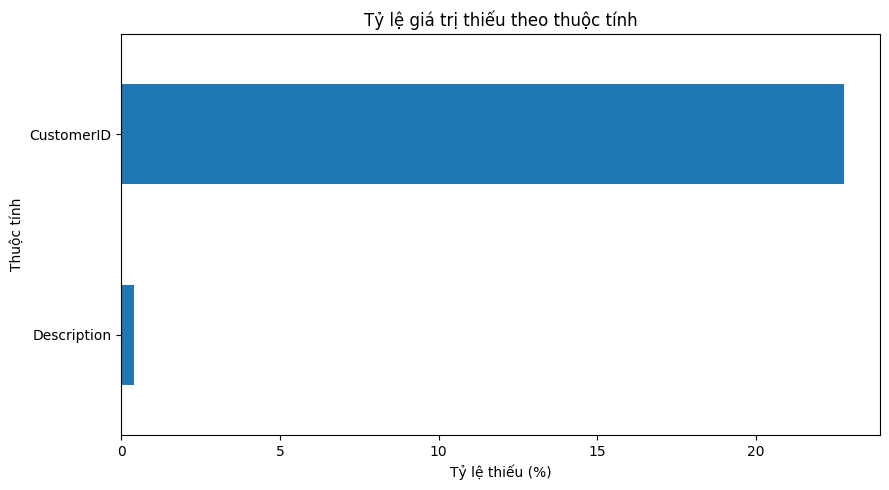

In [9]:
missing_plot = missing_summary[missing_summary["Missing_Count"] > 0].sort_values("Missing_Percent")
if not missing_plot.empty:
    ax = missing_plot["Missing_Percent"].plot(kind="barh", figsize=(9, 5))
    ax.set_title("Tỷ lệ giá trị thiếu theo thuộc tính")
    ax.set_xlabel("Tỷ lệ thiếu (%)")
    ax.set_ylabel("Thuộc tính")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "01_missing_values.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
else:
    print("Không phát hiện giá trị thiếu trong các cột hiện tại.")

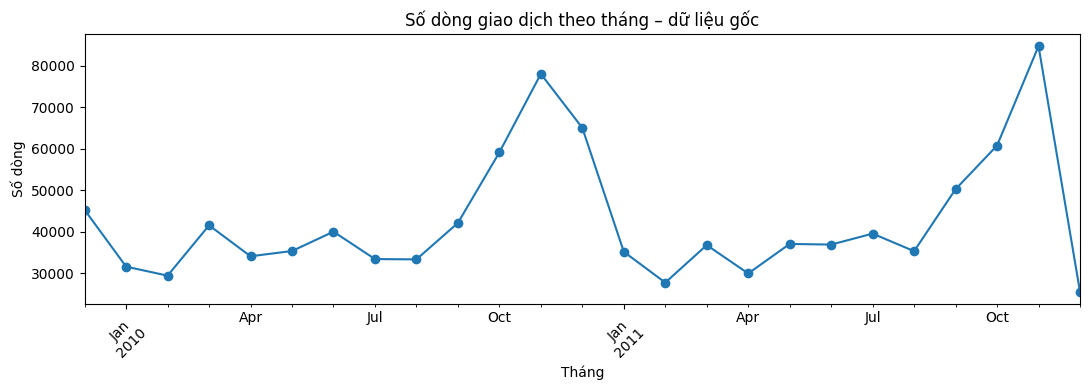

In [10]:
monthly_rows = (
    df.dropna(subset=["InvoiceDate"])
      .assign(Month=lambda x: x["InvoiceDate"].dt.to_period("M").dt.to_timestamp())
      .groupby("Month")
      .size()
)

if not monthly_rows.empty:
    ax = monthly_rows.plot(figsize=(11, 4), marker="o")
    ax.set_title("Số dòng giao dịch theo tháng – dữ liệu gốc")
    ax.set_xlabel("Tháng")
    ax.set_ylabel("Số dòng")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "02_raw_rows_by_month.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

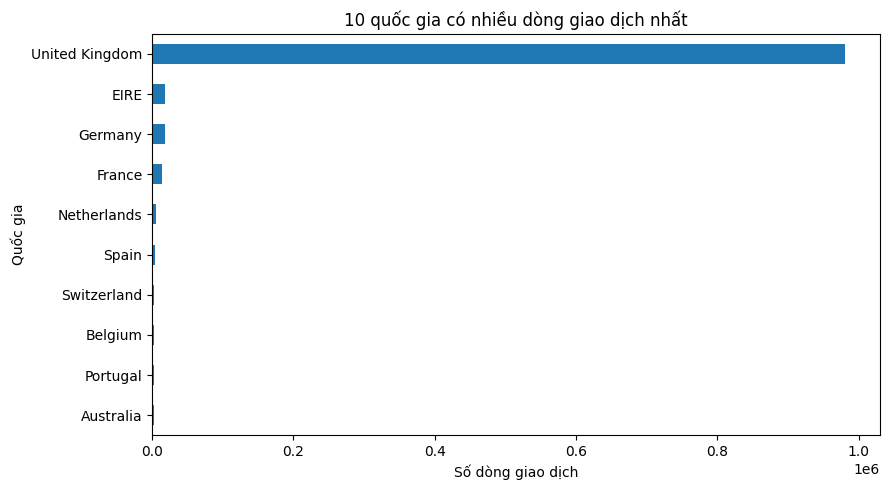

In [11]:
if "Country" in df.columns:
    country_rows = df["Country"].fillna("(Thiếu thông tin)").value_counts().head(10).sort_values()
    ax = country_rows.plot(kind="barh", figsize=(9, 5))
    ax.set_title("10 quốc gia có nhiều dòng giao dịch nhất")
    ax.set_xlabel("Số dòng giao dịch")
    ax.set_ylabel("Quốc gia")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_top_countries_by_rows.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

## 7. Tiền xử lý cho phân tích RFM

Ở bước xây RFM, mục tiêu là mô tả **hành vi mua hàng dương** của khách hàng. Notebook áp dụng quy tắc minh bạch như sau:

1. Loại bản ghi trùng hoàn toàn sau khi đã thống kê số lượng.
2. Loại bản ghi không có `CustomerID` vì không thể quy về khách hàng cụ thể.
3. Loại hóa đơn hủy có mã bắt đầu bằng `C`.
4. Loại giao dịch có `Quantity <= 0`, `UnitPrice <= 0` hoặc ngày giao dịch không hợp lệ.

Các dòng bị loại không bị xóa khỏi file gốc; quy tắc chỉ tạo ra bảng phân tích. Nếu thay đổi quy tắc, cần ghi nhận trong báo cáo và nhật ký thực nghiệm để có thể tái lập.

In [12]:
data_columns = [column for column in df.columns if column != "_source_sheet"]
raw_rows = len(df)
duplicate_rows = int(df.duplicated(subset=data_columns).sum())

prepared = df.drop_duplicates(subset=data_columns).copy()
after_dedup_rows = len(prepared)

before_customer_filter = len(prepared)
prepared = prepared[prepared["CustomerID"].notna()].copy()
removed_missing_customer = before_customer_filter - len(prepared)

invoice_text_prepared = prepared["InvoiceNo"].astype("string").str.strip().str.upper()
before_cancel_filter = len(prepared)
prepared = prepared[~invoice_text_prepared.str.startswith("C", na=False)].copy()
removed_cancellations = before_cancel_filter - len(prepared)

before_positive_filter = len(prepared)
positive_mask = (
    prepared["Quantity"].gt(0)
    & prepared["UnitPrice"].gt(0)
    & prepared["InvoiceDate"].notna()
)
prepared = prepared[positive_mask].copy()
removed_nonpositive_or_invalid = before_positive_filter - len(prepared)

# Chuẩn hóa CustomerID thành chuỗi để tránh xử lý mã khách hàng như số đo liên tục.
customer_ids_numeric = pd.to_numeric(prepared["CustomerID"], errors="coerce")
if customer_ids_numeric.notna().all():
    prepared["CustomerID"] = customer_ids_numeric.astype("Int64").astype(str)
else:
    prepared["CustomerID"] = prepared["CustomerID"].astype("string").str.strip()

prepared["Revenue"] = prepared["Quantity"] * prepared["UnitPrice"]
clean_df = prepared.reset_index(drop=True)

preprocessing_summary = pd.DataFrame({
    "Bước": [
        "Dữ liệu gốc",
        "Loại trùng hoàn toàn",
        "Loại thiếu CustomerID",
        "Loại hóa đơn hủy (mã bắt đầu bằng C)",
        "Loại Quantity <= 0, UnitPrice <= 0 hoặc ngày không hợp lệ",
        "Dữ liệu còn lại dùng cho RFM",
    ],
    "Số dòng bị loại ở bước": [
        0,
        duplicate_rows,
        removed_missing_customer,
        removed_cancellations,
        removed_nonpositive_or_invalid,
        0,
    ],
    "Số dòng sau bước": [
        raw_rows,
        after_dedup_rows,
        after_dedup_rows - removed_missing_customer,
        after_dedup_rows - removed_missing_customer - removed_cancellations,
        len(clean_df),
        len(clean_df),
    ],
})

display(preprocessing_summary)
preprocessing_summary.to_csv(TABLE_DIR / "preprocessing_summary.csv", index=False, encoding="utf-8-sig")
print(f"Tỷ lệ dòng giữ lại: {len(clean_df) / raw_rows * 100:.2f}%")

,Bước,Số dòng bị loại ở bước,Số dòng sau bước
0,Dữ liệu gốc,0,1067371
1,Loại trùng hoàn toàn,34335,1033036
2,Loại thiếu CustomerID,235151,797885
3,Loại hóa đơn hủy (mã bắt đầu bằng C),18390,779495
4,"Loại Quantity <= 0, UnitPrice <= 0 hoặc ngày k...",70,779425
5,Dữ liệu còn lại dùng cho RFM,0,779425


Tỷ lệ dòng giữ lại: 73.02%


## 8. Khảo sát dữ liệu sau tiền xử lý

Chỉ số doanh thu trong notebook được tính bằng `Quantity × UnitPrice`, đơn vị tiền tệ là GBP theo mô tả dataset. Kết quả chỉ phản ánh các dòng được giữ lại theo quy tắc ở phần trên.

In [13]:
clean_summary = pd.Series({
    "Số dòng giao dịch giữ lại": len(clean_df),
    "Số khách hàng": clean_df["CustomerID"].nunique(),
    "Số hóa đơn": clean_df["InvoiceNo"].nunique(),
    "Số sản phẩm": clean_df["StockCode"].nunique() if "StockCode" in clean_df.columns else np.nan,
    "Số quốc gia": clean_df["Country"].nunique() if "Country" in clean_df.columns else np.nan,
    "Ngày giao dịch đầu tiên": clean_df["InvoiceDate"].min(),
    "Ngày giao dịch cuối cùng": clean_df["InvoiceDate"].max(),
    "Tổng giá trị giao dịch (GBP)": clean_df["Revenue"].sum(),
    "Giá trị giao dịch trung bình (GBP/dòng)": clean_df["Revenue"].mean(),
})
display(clean_summary.rename("Giá trị").to_frame())

,Giá trị
Số dòng giao dịch giữ lại,779425
Số khách hàng,5878
Số hóa đơn,36969
Số sản phẩm,4631
Số quốc gia,41
Ngày giao dịch đầu tiên,2009-12-01 07:45:00
Ngày giao dịch cuối cùng,2011-12-09 12:50:00
Tổng giá trị giao dịch (GBP),"17,374,804.27"
Giá trị giao dịch trung bình (GBP/dòng),22.29


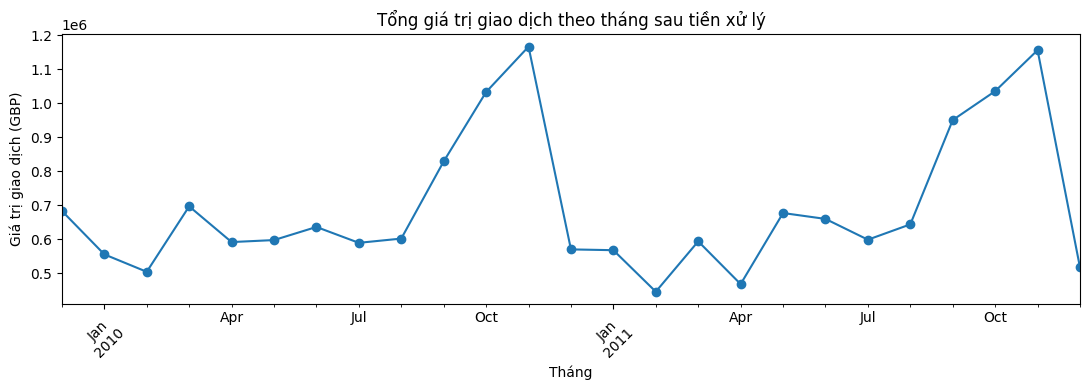

In [14]:
monthly_revenue = (
    clean_df.set_index("InvoiceDate")["Revenue"]
            .resample("MS")
            .sum()
)

ax = monthly_revenue.plot(figsize=(11, 4), marker="o")
ax.set_title("Tổng giá trị giao dịch theo tháng sau tiền xử lý")
ax.set_xlabel("Tháng")
ax.set_ylabel("Giá trị giao dịch (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_monthly_revenue_cleaned.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

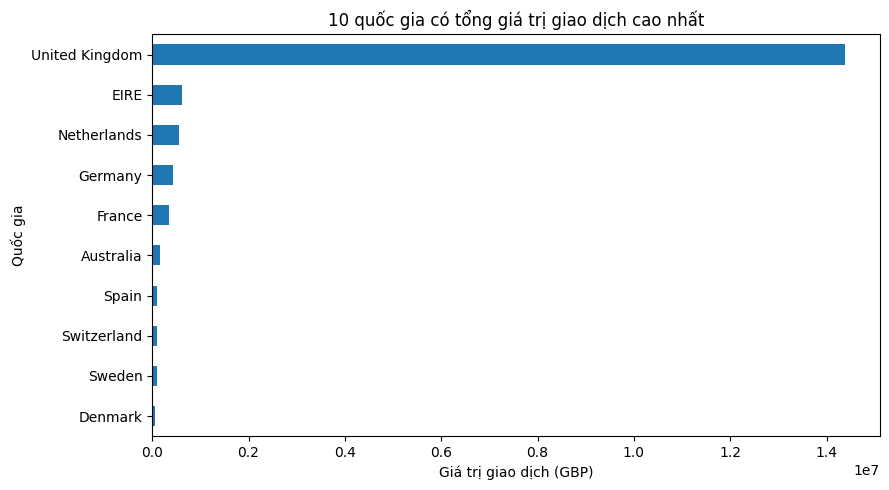

In [15]:
if "Country" in clean_df.columns:
    country_revenue = clean_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10).sort_values()
    ax = country_revenue.plot(kind="barh", figsize=(9, 5))
    ax.set_title("10 quốc gia có tổng giá trị giao dịch cao nhất")
    ax.set_xlabel("Giá trị giao dịch (GBP)")
    ax.set_ylabel("Quốc gia")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "05_top_countries_by_revenue.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

## 9. Tạo bảng RFM ban đầu

Ngày tham chiếu được lấy là **ngày sau giao dịch cuối cùng trong dữ liệu đã giữ lại**. Đây là quy ước phổ biến để khách hàng có giao dịch vào ngày cuối cùng nhận Recency bằng 1 ngày thay vì 0 ngày.

- `Recency`: càng nhỏ thì lần mua càng gần đây.
- `Frequency`: số hóa đơn khác nhau; không phải số dòng sản phẩm.
- `Monetary`: tổng giá trị giao dịch của khách hàng trong tập dữ liệu đã tiền xử lý.

In [16]:
reference_date = clean_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    clean_df.groupby("CustomerID")
    .agg(
        LastPurchaseDate=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum"),
        TransactionLines=("InvoiceNo", "size"),
    )
    .reset_index()
)
rfm["Recency"] = (reference_date - rfm["LastPurchaseDate"].dt.normalize()).dt.days
rfm = rfm[["CustomerID", "Recency", "Frequency", "Monetary", "TransactionLines", "LastPurchaseDate"]]
rfm = rfm.sort_values(["Monetary", "Frequency"], ascending=False).reset_index(drop=True)

print("Ngày tham chiếu RFM:", reference_date.date())
print("Số khách hàng trong bảng RFM:", f"{len(rfm):,}")
display(rfm.head(10))
display(rfm[["Recency", "Frequency", "Monetary", "TransactionLines"]].describe().T)

rfm.to_csv(TABLE_DIR / "rfm_table.csv", index=False, encoding="utf-8-sig")

Ngày tham chiếu RFM: 2011-12-10
Số khách hàng trong bảng RFM: 5,878


,CustomerID,Recency,Frequency,Monetary,TransactionLines,LastPurchaseDate
0,18102,1,145,"580,987.04",1040,2011-12-09 11:50:00
1,14646,2,151,"528,602.52",3849,2011-12-08 12:12:00
2,14156,10,156,"313,437.62",4038,2011-11-30 10:54:00
3,14911,2,398,"291,420.81",11077,2011-12-08 15:54:00
4,17450,9,51,"244,784.25",420,2011-12-01 13:29:00
5,13694,4,143,"195,640.69",1519,2011-12-06 09:32:00
6,17511,3,60,"172,132.87",1868,2011-12-07 10:12:00
7,16446,1,2,"168,472.50",3,2011-12-09 09:15:00
8,16684,5,55,"147,142.77",718,2011-12-05 14:06:00
9,12415,25,28,"144,458.37",926,2011-11-15 14:22:00


,count,mean,std,min,25%,50%,75%,max
Recency,"5,878.00",201.87,209.35,1.00,26.00,96.00,380.00,739.00
Frequency,"5,878.00",6.29,13.01,1.00,1.00,3.00,7.00,398.00
Monetary,"5,878.00","2,955.90","14,440.85",2.95,342.28,867.74,"2,248.30","580,987.04"
TransactionLines,"5,878.00",132.60,342.19,1.00,20.00,52.00,138.00,"12,435.00"


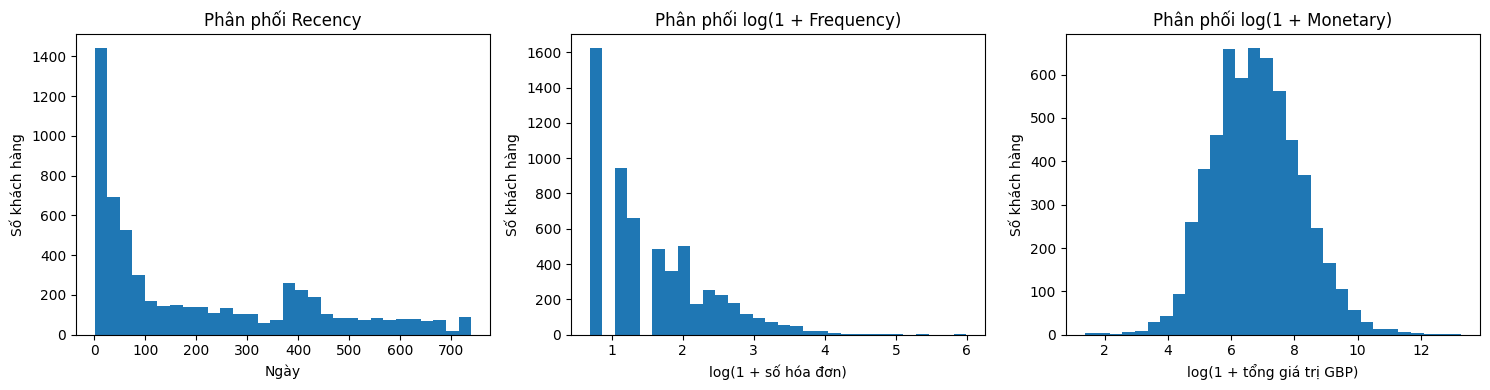

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(rfm["Recency"].dropna(), bins=30)
axes[0].set_title("Phân phối Recency")
axes[0].set_xlabel("Ngày")
axes[0].set_ylabel("Số khách hàng")

axes[1].hist(np.log1p(rfm["Frequency"].clip(lower=0)), bins=30)
axes[1].set_title("Phân phối log(1 + Frequency)")
axes[1].set_xlabel("log(1 + số hóa đơn)")
axes[1].set_ylabel("Số khách hàng")

axes[2].hist(np.log1p(rfm["Monetary"].clip(lower=0)), bins=30)
axes[2].set_title("Phân phối log(1 + Monetary)")
axes[2].set_xlabel("log(1 + tổng giá trị GBP)")
axes[2].set_ylabel("Số khách hàng")

plt.tight_layout()
plt.savefig(FIG_DIR / "06_rfm_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

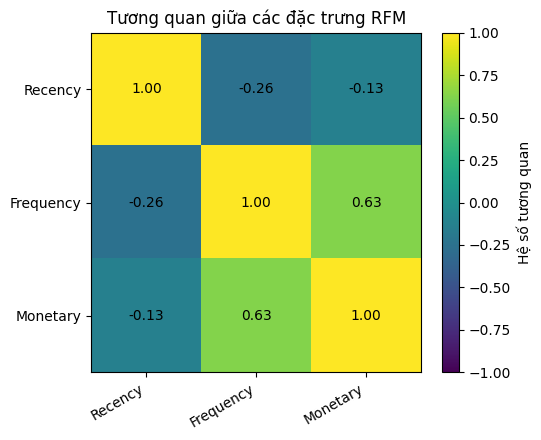

In [18]:
rfm_corr = rfm[["Recency", "Frequency", "Monetary"]].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(rfm_corr.values, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(rfm_corr.columns)), labels=rfm_corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(rfm_corr.index)), labels=rfm_corr.index)
for row in range(rfm_corr.shape[0]):
    for col in range(rfm_corr.shape[1]):
        ax.text(col, row, f"{rfm_corr.iloc[row, col]:.2f}", ha="center", va="center")
ax.set_title("Tương quan giữa các đặc trưng RFM")
fig.colorbar(image, ax=ax, label="Hệ số tương quan")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_rfm_correlation.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

## 10. Lưu tóm tắt EDA để phục vụ báo cáo tiến độ

Bảng tóm tắt chỉ ghi các con số có được sau khi notebook chạy với dataset gốc. Khi làm báo cáo giữa kỳ, dùng các giá trị thực tế này và chèn các biểu đồ được lưu trong `outputs/figures/`.

In [19]:
eda_summary = {
    "dataset_file": DATA_FILE.name,
    "raw_rows": int(raw_rows),
    "raw_columns_excluding_internal_sheet": int(len(data_columns)),
    "exact_duplicate_rows": int(duplicate_rows),
    "rows_missing_customer_id_in_raw": int(df["CustomerID"].isna().sum()),
    "cancellation_rows_in_raw": int(df["InvoiceNo"].astype("string").str.strip().str.upper().str.startswith("C", na=False).sum()),
    "rows_removed_missing_customer_id": int(removed_missing_customer),
    "rows_removed_cancellations_after_previous_step": int(removed_cancellations),
    "rows_removed_nonpositive_or_invalid_after_previous_steps": int(removed_nonpositive_or_invalid),
    "rows_used_for_rfm": int(len(clean_df)),
    "customers_in_rfm": int(rfm["CustomerID"].nunique()),
    "invoices_in_rfm": int(clean_df["InvoiceNo"].nunique()),
    "reference_date": str(reference_date.date()),
    "min_transaction_date_used": str(clean_df["InvoiceDate"].min()),
    "max_transaction_date_used": str(clean_df["InvoiceDate"].max()),
    "total_revenue_gbp_in_cleaned_transactions": float(clean_df["Revenue"].sum()),
}

eda_summary_df = pd.DataFrame([eda_summary])
display(eda_summary_df.T.rename(columns={0: "Giá trị"}))
eda_summary_df.to_csv(TABLE_DIR / "eda_summary.csv", index=False, encoding="utf-8-sig")

,Giá trị
dataset_file,online_retail_II.xlsx
raw_rows,1067371
raw_columns_excluding_internal_sheet,8
exact_duplicate_rows,34335
rows_missing_customer_id_in_raw,243007
cancellation_rows_in_raw,19494
rows_removed_missing_customer_id,235151
rows_removed_cancellations_after_previous_step,18390
rows_removed_nonpositive_or_invalid_after_previous_steps,70
rows_used_for_rfm,779425
